In [1]:
import numpy as np 
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

## 量化海马中的细胞类型差异

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/Finished_analysis/metaneighbor_score/hmdata_full_harmony.h5ad')
scdata = scdata[scdata.obs['tissues'] == 'HM']
scdata

View of AnnData object with n_obs × n_vars = 36611 × 3000
    obs: 'species', 'tissues', 'samples', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'cluster', 'celltype', 'coarse_celltype'
    var: 'gene_ids', 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'celltype_colors', 'cluster_colors', 'coarse_celltype_colors', 'dendrogram_leiden', 'hvg', 'leiden', 'log1p', 'neighbors', 'pca', 'samples_colors', 'species_colors', 'tissues_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'harmony_0', 'umap_0'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

In [3]:


metric_key = 'euclidean' #'cosine' #'cosine'

cell_res = {}
for cell in scdata.obs.celltype.unique():
    res_dic = {}
    adata = scdata[scdata.obs['celltype'] == cell,:] # celltype spcific data
    for species in ['CY','JT','T','QF','M']:
        species_idx = adata.obs['species'] == species 
        subdata = adata[species_idx,:] 

        # idx = np.arange(subdata.shape[0])
        # sel_idx = np.random.choice(idx, size = 500)
        meta_cell = subdata.X.toarray().mean(axis = 0)
        res_dic[species] = meta_cell 

    res_df = pd.DataFrame(res_dic).T
    sim_df = squareform(pdist(res_df, metric = metric_key))
    score = 2*(sim_df[:3,3:].mean()) - (sim_df[:3,:3].sum()/6 + sim_df[3:,3:].sum()/2)
    cell_res[cell] = score 

print(cell_res)

{'excitatory neuron': 14.711689016717685, 'OPC': 11.69481463065614, 'inhibitory neuron': 9.845195220649103, 'astrocyte': 4.497415819331309, 'microglia': -0.5225027651340213, 'oligodendrocyte': 4.391284221629704, 'ependymal': 5.682839196857671}


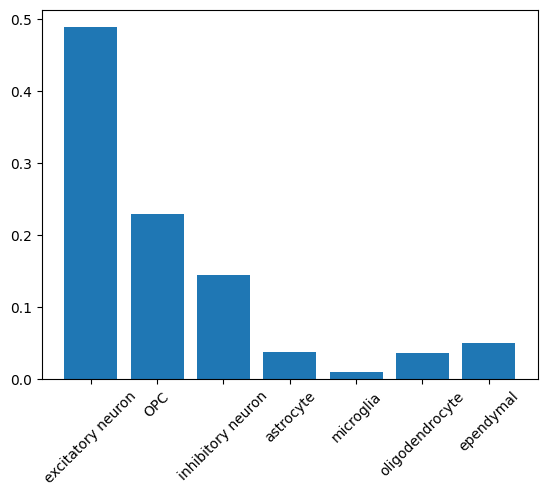

In [4]:
diff = np.array(list(cell_res.values()))
tmp = np.exp(diff/4)
tmp = tmp/tmp.sum()
plt.bar(x =cell_res.keys(), height = tmp)
plt.xticks(rotation = 45)
plt.show()

In [5]:
from scipy import stats
import numpy as np

data = tmp[1:]#np.concatenate([tmp[:2], tmp[3:]]) 
mu0 = tmp[0]

# mu0 = tmp[1]
# data = np.concatenate([tmp[:1], tmp[2:]])

delta = data - mu0

stat, p_one_tailed = stats.wilcoxon(delta, alternative='less')

# mean_diff = np.max(delta)
# if mean_diff < 0:
#     p_one_tailed = p_two_tailed / 2
# else:
#     p_one_tailed = 1 - p_two_tailed / 2

# print(f"Sample median: {mean_diff :.4f}")
print(f"Wilcoxon stat: {stat:.4f}")
print(f"One-tailed p-value (H1: median < {mu0}): {p_one_tailed:.4f}")

alpha = 0.05
if p_one_tailed < alpha:# and mean_diff < 0:
    print(f"✅ 拒绝 H0：中位数显著低于 {mu0}")
else:
    print(f"❌ 无法拒绝 H0：中位数不显著低于 {mu0}")

Wilcoxon stat: 0.0000
One-tailed p-value (H1: median < 0.48852008276148967): 0.0156
✅ 拒绝 H0：中位数显著低于 0.48852008276148967


In [6]:
p_one_tailed

0.015625

In [ ]:
# 假设检验说明：

# 对于5个物种，给定一组细胞cluster, 检验

## 更严格的检验

In [7]:

metric_key = 'euclidean' #'cosine' #'cosine'

data_list = []
for k in range(20):
    cell_res = {}
    for cell in scdata.obs.celltype.unique():
        res_dic = {}
        adata = scdata[scdata.obs['celltype'] == cell,:] # celltype spcific data
        for species in ['CY','JT','T','QF','M']:
            species_idx = adata.obs['species'] == species 
            subdata = adata[species_idx,:] 

            idx = np.arange(subdata.shape[0])
            sel_idx = np.random.choice(idx, size = 100)
            meta_cell = subdata[sel_idx,:].X.toarray().mean(axis = 0)
            res_dic[species] = meta_cell 

        res_df = pd.DataFrame(res_dic).T
        sim_df = squareform(pdist(res_df, metric = metric_key))
        score = 2*(sim_df[:3,3:].mean()) - (sim_df[:3,:3].sum()/6 + sim_df[3:,3:].sum()/2)
        cell_res[cell] = score 

    data_list.append(cell_res)
df = pd.DataFrame(data_list)
df

,excitatory neuron,OPC,inhibitory neuron,astrocyte,microglia,oligodendrocyte,ependymal
0,13.938063,11.281689,10.603525,4.237969,-0.458310,4.387708,5.173517
1,14.004946,12.141844,10.007316,4.781001,-0.779599,4.903575,5.365594
2,14.963869,11.232197,8.196096,4.635743,-0.589646,4.252948,5.655904
3,14.858177,11.714413,10.396300,4.536030,-0.092402,4.618329,5.298683
4,14.720724,10.979012,8.881661,4.173602,-0.849019,4.546120,5.054735
5,14.167822,11.474385,8.547219,4.388271,-0.786674,4.031311,5.296383
6,14.832406,11.034413,10.113444,4.190624,-0.504236,4.126022,6.023147
7,12.881308,12.276355,9.067446,4.748351,-0.527636,4.131064,4.918136
8,15.076368,11.586618,8.802399,4.169195,-0.719216,4.229635,5.961629
9,13.976664,11.127058,9.351598,4.690113,-0.622524,4.103496,5.372248


In [21]:
X = df.values 
t = 4 
exp_x = np.exp(X/4)
exp_sum = exp_x.sum(axis = 1, keepdims = True)
prob = exp_x / exp_sum
df = pd.DataFrame(prob, index = df.index, columns = df.columns)

In [22]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from scipy import stats

# 假设 df 是一个 DataFrame，列名为8个脑区，每列有 K 行
# 例如: df.columns = ['hippocampus', 'ctx1', 'ctx2', ..., 'thalamus']

hippo = df['excitatory neuron'].values
other_regions = [col for col in df.columns if col != 'excitatory neuron']

pvals = []
stat_idx= []

for region in other_regions:
    
    y = df[region].values
    # delta = y - hippo
    # print(region, delta.min())
    # stat, p_one_sided = stats.wilcoxon(delta, alternative='less')
    # # 单侧 t 检验：注意 ttest_ind 默认是双侧
    t_stat, p_two_sided = ttest_ind(hippo, y, equal_var=False)  # 可设 equal_var=False 用 Welch's t-test
    
    # 转换为单侧 p 值（因为我们关心 hippo > region）
    if t_stat > 0:
        p_one_sided = p_two_sided / 2
    else:
        p_one_sided = 1 - p_two_sided / 2  # 实际不会显著，但逻辑完整
    
    stat_idx.append(t_stat)
    pvals.append(p_one_sided)

# FDR 校正（Benjamini-Hochberg）
reject, pvals_corrected, _, _ = multipletests(pvals, alpha=0.05, method='fdr_bh')

# 整理结果
results = pd.DataFrame({
    'Comparison': [f'excitatory neuron vs {r}' for r in other_regions],
    't_statistic': stat_idx,
    'p_raw': pvals,
    'p_fdr': pvals_corrected,
    'significant (FDR<0.05)': reject
})

results

,Comparison,t_statistic,p_raw,p_fdr,significant (FDR<0.05)
0,excitatory neuron vs OPC,17.921901,1.297421e-18,1.297421e-18,True
1,excitatory neuron vs inhibitory neuron,24.643647,3.591923e-23,2.155154e-22,True
2,excitatory neuron vs astrocyte,38.550957,4.673624e-20,7.010435e-20,True
3,excitatory neuron vs microglia,41.305379,2.217217e-20,6.651652e-20,True
4,excitatory neuron vs oligodendrocyte,38.607907,4.009103e-20,7.010435e-20,True
5,excitatory neuron vs ependymal,37.475504,7.458765e-20,8.950518e-20,True


In [16]:
results.to_csv('celltype_diff_p.csv')

In [23]:
df

,excitatory neuron,OPC,inhibitory neuron,astrocyte,microglia,oligodendrocyte,ependymal
0,0.440786,0.226890,0.191507,0.038999,0.012055,0.040487,0.049275
1,0.427655,0.268417,0.157419,0.042620,0.010614,0.043947,0.049327
2,0.543487,0.213810,0.100089,0.041099,0.011130,0.037348,0.053038
3,0.487343,0.222078,0.159732,0.036908,0.011604,0.037675,0.044661
4,0.530642,0.208234,0.123263,0.037989,0.010823,0.041697,0.047351
5,0.486851,0.248290,0.119439,0.042227,0.011581,0.038622,0.052990
6,0.508861,0.196896,0.156403,0.035578,0.011001,0.035008,0.056253
7,0.375977,0.323206,0.144903,0.049219,0.013161,0.042181,0.051354
8,0.531960,0.222323,0.110839,0.034806,0.010254,0.035335,0.054483
9,0.469414,0.230231,0.147705,0.046055,0.012203,0.039773,0.054619
